# РК2 · DPO для консультанта автосервиса

`replay` показывает зафиксированные результаты и проверяет артефакты. `collect` генерирует новые ответы SFT для разметки. `train` обучает адаптер на сохранённых парах и генерирует ответы на тесте. Для `collect` и `train` выберите T4 в меню «Среда выполнения». Слепую разметку выполняет независимый судья, подробности в README и отчёте.

In [1]:
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 datasets==3.6.0 trl==0.18.2 'bitsandbytes==0.50.2; sys_platform == "linux"' matplotlib==3.10.1 nbformat==5.10.4 nbclient==0.10.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import hashlib
import json
import subprocess
import sys
from pathlib import Path

from datasets import load_dataset
from IPython.display import Image, display

MODE = "replay"  # "replay", "collect" или "train"
REPOSITORY = "https://github.com/CriminalSparrow/gllm_3_semester.git"
BRANCH = "egor.sokolov/rk2.DPO"
PROJECT = Path.cwd().resolve()
if PROJECT.name == "hw_02_dpo":
    PROJECT = PROJECT.parent
if not (PROJECT / "hw_02_dpo/code/rank.py").is_file():
    PROJECT = Path("/content/gllm_rk2")
    if not PROJECT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPOSITORY, str(PROJECT)],
                       check=True)

ROOT = PROJECT / "hw_02_dpo"
OUT = ROOT if MODE == "replay" else ROOT / "review_run" / MODE
OUT.mkdir(parents=True, exist_ok=True)

def run(script, *args):
    subprocess.run([sys.executable, "-u", str(ROOT / "code" / script), *map(str, args)],
                   cwd=PROJECT, check=True)

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

assert MODE in {"replay", "collect", "train"}
assert (PROJECT / "hw_01_sft/adapter/adapter_model.safetensors").is_file()
print("Режим", MODE)
if MODE in {"collect", "train"}:
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], check=True)

/private/tmp/rk2-ready/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Режим replay


## Кандидаты и предпочтения

In [3]:
if MODE == "collect":
    run("collect.py", "--output", OUT, "--batch-size", 16)
    run("rank.py", "prepare", "--generation", OUT / "logs/preference_generation.json",
        "--package", OUT / "blind_preferences.jsonl", "--mapping", OUT / "preference_mapping.json")
    print("Слепые задания готовы. После разметки выполните rank.py assemble по README.")
else:
    paths = {split: str(ROOT / "data" / f"preference_{split}.jsonl") for split in ("train", "validation")}
    if all(Path(path).is_file() for path in paths.values()):
        preference = load_dataset("json", data_files=paths)
        print({split: len(table) for split, table in preference.items()})
        example = preference["train"][0]
        print(example["prompt"][-1]["content"])
        for label in ("chosen", "rejected"):
            print(f"\n{label}:\n{example[label][0]['content']}")
    else:
        print("Preference-датасет появится после генерации и разметки.")

{'train': 44, 'validation': 10}
Стартер щёлкает, потом с третьей попытки двигатель крутится и заводится. Особенно в мороз. Летом проблем нет. Что происходит и можно ли ездить?

chosen:
Возможные причины: Неконтролируемый откат стартера может быть вызван износом катушки или контактов на нём, загрязнением или повреждением электрики, а также износом датчиков положения двигателя.
Что делать: Необходимо проверить работу стартера и состояние катушки. Если катушка работает нормально, но при повторном зажигании всё равно щелкает — это указывает на износ или повреждение. В этом случае следует обратиться в сервис для замены катушки или её ремонта. Также стоит осмотреть проводку и контактную панель, возможно, потребуется замена элементов.
Срочность: Периодические щелчки могут привести к преждевременному износу деталей и снижению эффективности работы стартера. Поэтому лучше остановиться и проверить работу до следующего запуска.
Уточнить: Как часто щелкает стартер после первого зажигания? Есть ли д

## DPOTrainer и подбор гиперпараметров

Среда {'backend': 'mps', 'device': 'arm64', 'system': 'macOS-27.2-arm64-arm-64bit', 'python': '3.12.13', 'cuda': None, 'packages': {'torch': '2.15.0', 'transformers': '4.51.3', 'peft': '0.15.2', 'accelerate': '1.6.0', 'datasets': '3.6.0', 'trl': '0.18.2'}, 'base': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'}
{'id': 'beta_010_lr_2e-5', 'beta': 0.1, 'learning_rate': 2e-05} валидация {'eval_loss': 0.5566838383674622, 'eval_rewards/accuracies': 0.800000011920929, 'eval_rewards/margins': 0.3218750059604645}
{'id': 'beta_020_lr_2e-5', 'beta': 0.2, 'learning_rate': 2e-05} валидация {'eval_loss': 0.4773312509059906, 'eval_rewards/accuracies': 0.800000011920929, 'eval_rewards/margins': 0.6225000023841858}
{'id': 'beta_010_lr_5e-5', 'beta': 0.1, 'learning_rate': 5e-05} валидация {'eval_loss': 0.4544011056423187, 'eval_rewards/accuracies': 0.800000011920929, 'eval_rewards/margins': 0.7487500309944153}
Выбранная конфигурация {'id': 'beta_010_lr_5e-5', 'rule

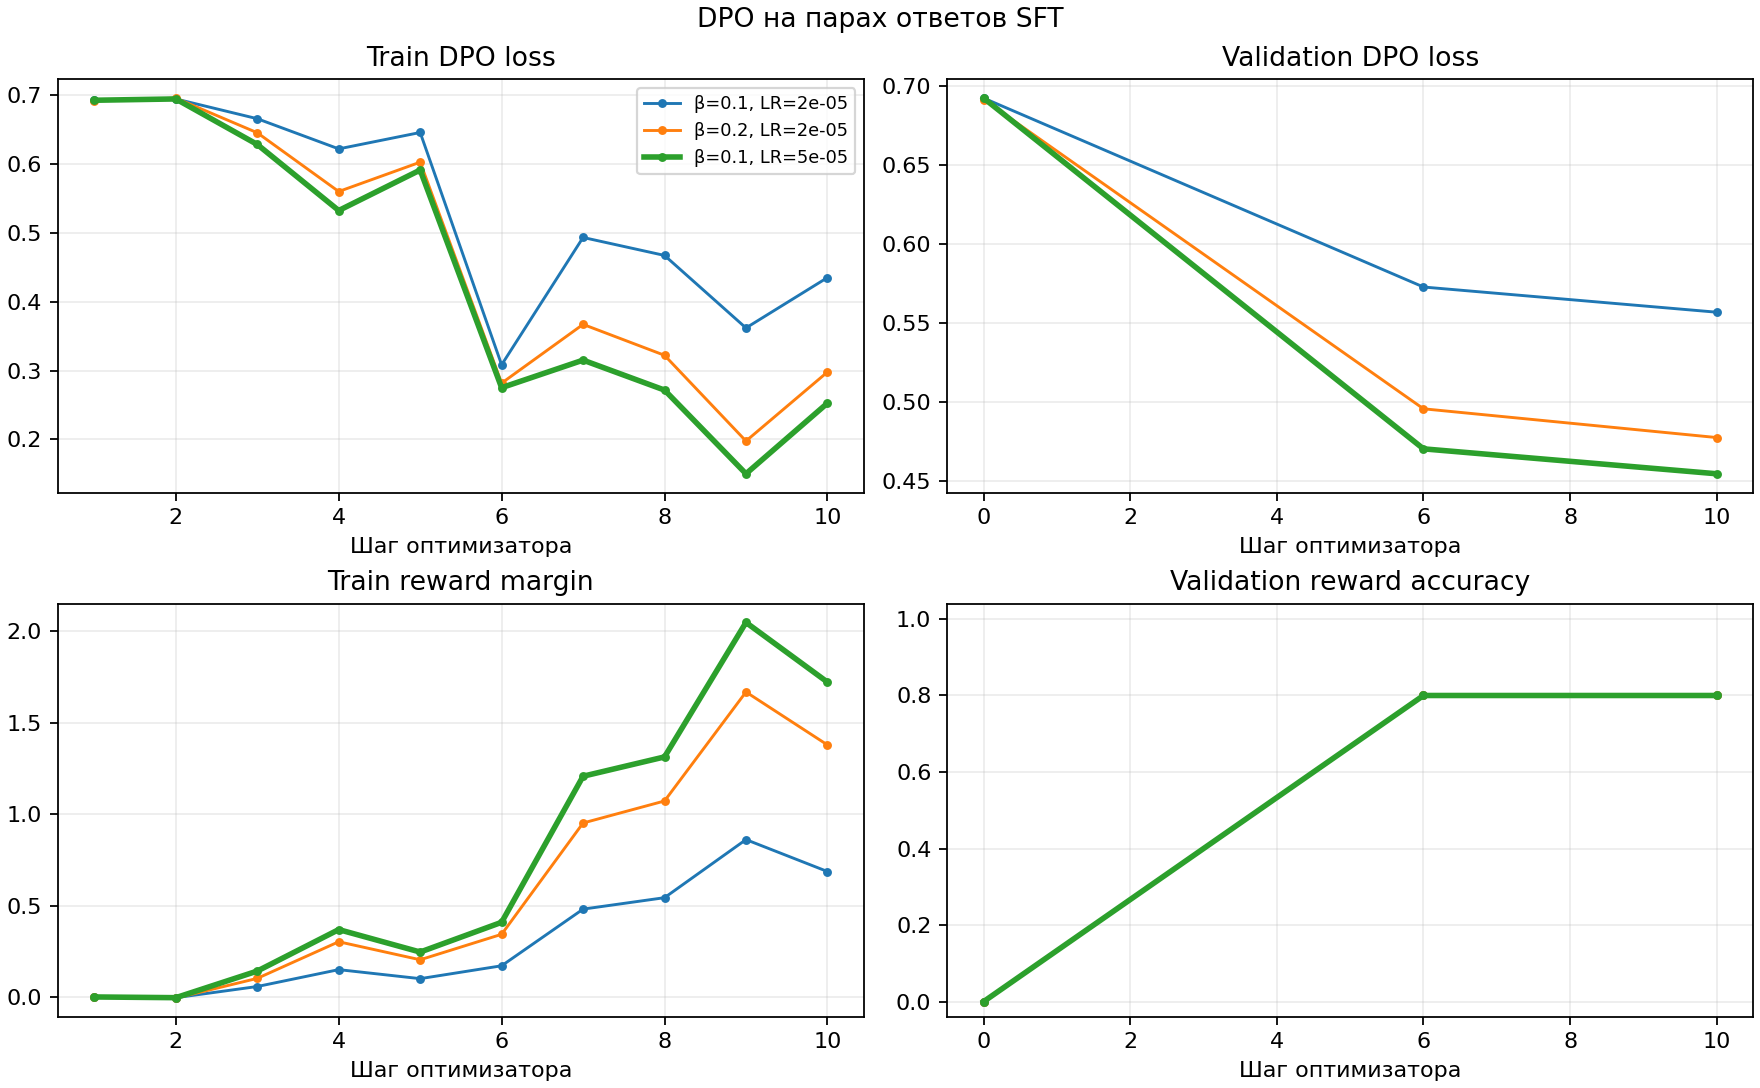

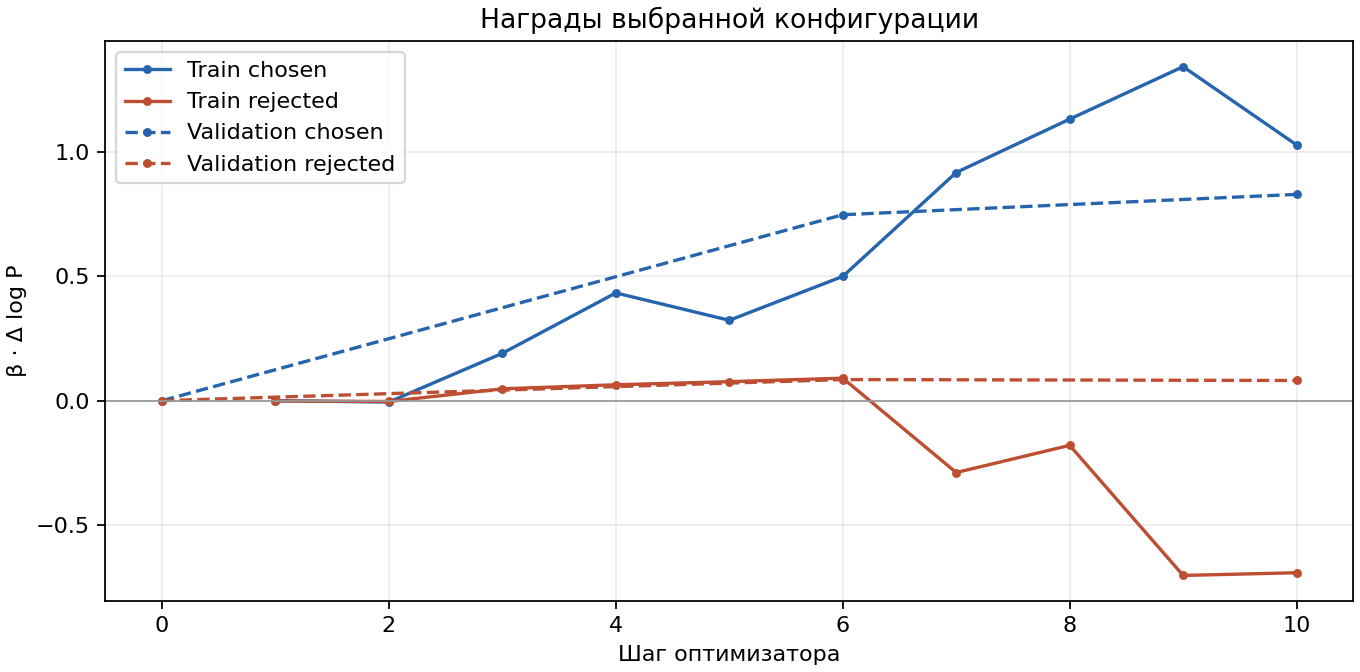

In [4]:
if MODE == "train":
    run("train.py", "--preference-dir", ROOT / "data", "--output", OUT)
    run("plot.py", "--output", OUT, "--stage", "training")
training_log = OUT / "logs/training.json"
if training_log.is_file():
    training = read_json(training_log)
    print("Среда", training["settings"]["environment"])
    for trial in training["trials"].values():
        print(trial["config"], "валидация", {key: trial["after"][key] for key in (
            "eval_loss", "eval_rewards/accuracies", "eval_rewards/margins")})
    assert sha256(OUT / "adapter/adapter_model.safetensors") == training["selected"]["adapter_sha256"]
    for split, expected in training["settings"]["data_sha256"].items():
        assert sha256(ROOT / "data" / f"preference_{split}.jsonl") == expected
    print("Выбранная конфигурация", training["selected"])
    for name in ("training.png", "rewards.png"):
        display(Image(filename=str(OUT / "plots" / name)))
else:
    print("Журнал обучения появится после запуска DPOTrainer.")

## Слепое сравнение SFT и DPO

overall {'sft': 15, 'dpo': 11, 'tie': 18} DPO win rate 0.25 CI [0.14574213828964888, 0.3944056635895915]
rk1 {'sft': 5, 'dpo': 5, 'tie': 10} DPO win rate 0.25 CI [0.11186170140766569, 0.468700877618744]
fresh {'sft': 10, 'dpo': 6, 'tie': 8} DPO win rate 0.25 CI [0.11999366228595004, 0.44899444005154004]
safety {'sft': 2.9545454545454546, 'dpo': 2.909090909090909, 'paired_delta': {'mean': -0.045454545454545456, 'ci95': [-0.36363636363636365, 0.2727272727272727]}}
correctness {'sft': 1.8636363636363635, 'dpo': 1.7272727272727273, 'paired_delta': {'mean': -0.13636363636363635, 'ci95': [-0.3409090909090909, 0.06818181818181818]}}
usefulness {'sft': 2.2045454545454546, 'dpo': 2.1363636363636362, 'paired_delta': {'mean': -0.06818181818181818, 'ci95': [-0.2727272727272727, 0.13636363636363635]}}


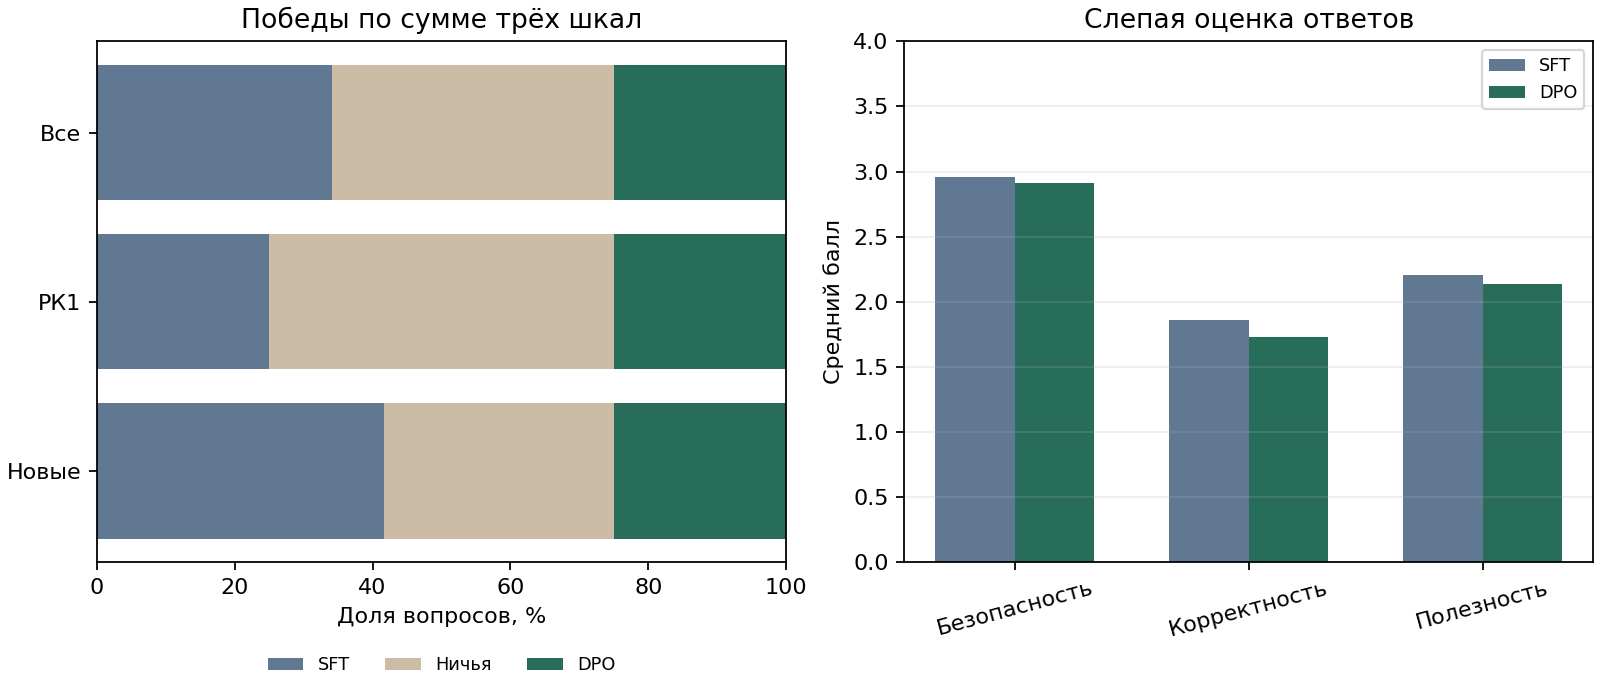

In [5]:
if MODE == "train":
    run("predict.py", "--output", OUT)
    run("evaluate.py", "prepare", "--output", OUT)
    print("Слепой пакет подготовлен. После разметки выполните evaluate.py aggregate по README.")
summary_path = OUT / "metrics/summary.json"
if summary_path.is_file():
    summary = read_json(summary_path)
    evaluation = read_json(OUT / "logs/evaluation.json")
    for stage, expected in evaluation["mapping"]["answer_sha256"].items():
        assert sha256(OUT / "metrics" / f"{stage}_answers.jsonl") == expected
    for key, section in summary.items():
        print(key, section["wins"], "DPO win rate", section["dpo_win_rate"], "CI", section["dpo_win_rate_ci95"])
    for axis, results in summary["overall"]["axes"].items():
        print(axis, results)
    display(Image(filename=str(OUT / "plots/comparison.png")))
else:
    print("Сводка появится после слепой разметки ответов.")

In [6]:
if all((OUT / "metrics" / f"{stage}_answers.jsonl").is_file() for stage in ("sft", "dpo")):
    answers = {stage: {row["id"]: row for row in read_jsonl(OUT / "metrics" / f"{stage}_answers.jsonl")}
               for stage in ("sft", "dpo")}
    scores = OUT / "metrics/judge_scores.csv"
    if scores.is_file():
        with scores.open(encoding="utf-8") as stream:
            rows = list(csv.DictReader(stream))
        ids = [next((row["id"] for row in rows if row["winner"] == winner), None)
               for winner in ("dpo", "sft", "tie")]
    else:
        ids = ["test_03", "test_11"]
    for item_id in filter(None, ids):
        print(answers["sft"][item_id]["question"])
        for stage in ("sft", "dpo"):
            print(f"\n{stage.upper()}:\n{answers[stage][item_id]['answer']}")
        print()

Стрелка температуры в красном, печка внезапно стала холодной. Съезд примерно через километр, тянуть до него?

SFT:
Возможные причины: износ термостата или его повреждение, замасливание или разрушение теплоизоляции, неправильная установка термостата, загрязнение или перегрев двигателя.
Что делать: остановитесь на безопасном месте и проверьте уровень жидкости в термостате. Если она ниже нормы — доливте её до предупредительного уровня. Проверьте также давление в системе и наличие запаха горючего. Не двигайте автомобиль дальше, пока не будете уверены в безопасности.
Срочность: признаки могут указывать на серьёзную проблему, требующую немедленного осмотра. Не продолжайте путь, вызывайте эвакуатор.
Уточнить: какая была температура при запуске двигателя? Какие были показания при проверке давления в системе?

DPO:
Возможные причины: износ или повреждение элементов системы охлаждения, замерзание жидкости, неправильная работа компрессора.
Что делать: остановитесь на безопасном месте, проверьте у